# Pandas Lab: reading online discussions

We work with **SynDisco**, a dataset of *synthetic* online discussions: seven simulated users debate a topic, and an LLM moderator may or may not step in. The same setup was run with 6 different LLMs and 4 moderation conditions, 30 times each: **720 conversations**.

We learn pandas by asking simple questions about this data: how is it stored, how long are the conversations, who speaks, and what does the moderator change?

| Part | Topic | What we use |
|---|---|---|
| 1 | Loading data | JSON files, `pd.DataFrame`, one table from many files |
| 2 | Simple exploration | `head`, `info`, `describe`, missing values, a first cleaning step |
| 3 | Selecting rows and columns | `loc`, `iloc`, slices, labels, rows and columns together |
| 4 | Math and statistics | `min`, `mean`, `mode`, `value_counts`, changing values |
| 5 | Filtering and text | boolean filters, slicing text, regex, `drop`, `pop` |
| 6 | Operations between columns | arithmetic between columns, strings, preprocessing |
| 7 | Dates and times | `to_datetime`, parts of a date, differences |
| 8 | Groups and joins | `groupby`, `concat`, `merge` |

**How to read this notebook.** Every part is a section with its own heading, so you can collapse the parts you are not working on (click the arrow next to a heading in Colab, VS Code or JupyterLab). Start each part with its goals, and read the findings at its end. Run the cells from top to bottom.

## Setup

Run **one** of the next two cells to download the data: the first on Colab, Linux or Mac, the second on any system (for example Windows). Then run the imports.

In [1]:
# download and unzip the data (Colab / Linux / Mac) -- on Windows run the next cell instead
!wget -q https://github.com/dimits-ts/syndisco/raw/master/viewer_datasets/online.zip
!unzip -qo online.zip

'wget' is not recognized as an internal or external command,
operable program or batch file.
'unzip' is not recognized as an internal or external command,
operable program or batch file.


In [2]:
# download and unzip the data (any OS, e.g. Windows) -- skip if you ran the cell above
import urllib.request
import zipfile

url = "https://github.com/dimits-ts/syndisco/raw/master/viewer_datasets/online.zip"
urllib.request.urlretrieve(url, "online.zip")

with zipfile.ZipFile("online.zip") as z:
    z.extractall()

In [3]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

## Part 1 · Loading the data

> **Goal.** Go from a folder of JSON files to a single pandas table.
>
> **What we do.** Look at the folder and at one file, see why the obvious `pd.read_json` fails, then read every file in a loop and build one DataFrame with one row per conversation.

### 1.1 What is in the download?

The zip unpacks into one folder per experimental condition: 6 models × 4 moderation settings = 24 folders (names like `llama70b_vanilla.txt`; `nomod` means no moderator).

In [4]:
# what is inside the folder?
data_dir = Path("online")
folders = sorted(data_dir.iterdir())

print(len(folders), "folders inside", data_dir)
print("folder name = <model>_<moderation setting>   (nomod = no moderator)")
print("the first five:")
for f in folders[:5]:
    print("  ", f.name)

24 folders inside online
folder name = <model>_<moderation setting>   (nomod = no moderator)
the first five:
   llama70b_constructive_communications.txt
   llama70b_erulemaking.txt
   llama70b_nomod
   llama70b_vanilla.txt
   llama8b_constructive_communications.txt


In [5]:
# how many files in one folder?
files = sorted(folders[0].glob("*.json"))
print("Each nodel file contains", len(files), "json files")

Each nodel file contains 30 json files


In [6]:
# what are those files? one file per conversation, named by the time it was created
print("the first five files in", folders[0].name)
for f in files[:5]:
    print("  ", f.name)

the first five files in llama70b_constructive_communications.txt
   26-02-09-19-01-51.json
   26-02-09-19-19-58.json
   26-02-09-19-34-50.json
   26-02-09-19-49-59.json
   26-02-09-20-07-39.json


### 1.2 One conversation

Each file is one conversation. Its keys are `timestamp`, `id`, `users`, `moderator`, `ctx_length` and `logs`, where `logs` is the list of messages.

In [7]:
# open one conversation file
first_file = files[0]
with open(first_file) as f:
    raw = json.load(f)

print("file:", first_file.name)
print("json.load gives a", type(raw).__name__, "with these keys:")
for key, value in raw.items():
    size = f" ({len(value)} items)" if isinstance(value, list) else ""
    print(f"  {key:<11} {type(value).__name__}{size}")

file: 26-02-09-19-01-51.json
json.load gives a dict with these keys:
  timestamp   str
  id          str
  users       list (7 items)
  moderator   str
  ctx_length  int
  logs        list (32 items)


In [8]:
# first two messages of the conversation
print("Logs has many messages. Each message is a dict with the keys:", list(raw["logs"][0].keys()))
print()
for msg in raw["logs"][:2]:
    print(msg["name"], "| written by:", msg["model"])
    print("   ", msg["text"][:120] + "...")
print()
print("(hardcoded = a real comment copied from an online discussion, not written by a model)")

Logs has many messages. Each message is a dict with the keys: ['name', 'text', 'model', 'prompt']

grave-convergence | written by: hardcoded
    Not all Trump voters do it based out of hate and fear. What about all of his other messages? Making trade deals that ben...
camel-conduit | written by: hardcoded
    So far, he's only showed that he can get attention within one party. If he wins the White House, hate and fear mongering...

(hardcoded = a real comment copied from an online discussion, not written by a model)


### 1.3 Why not just `pd.read_json`?

The file is not a flat table: `logs` is a list of messages, so pandas cannot line the keys up and raises `ValueError: All arrays must be of the same length`. The call is commented out so the notebook runs top to bottom; remove the `#` to see the error. Wrapping the dict in a list gives a table with one row.

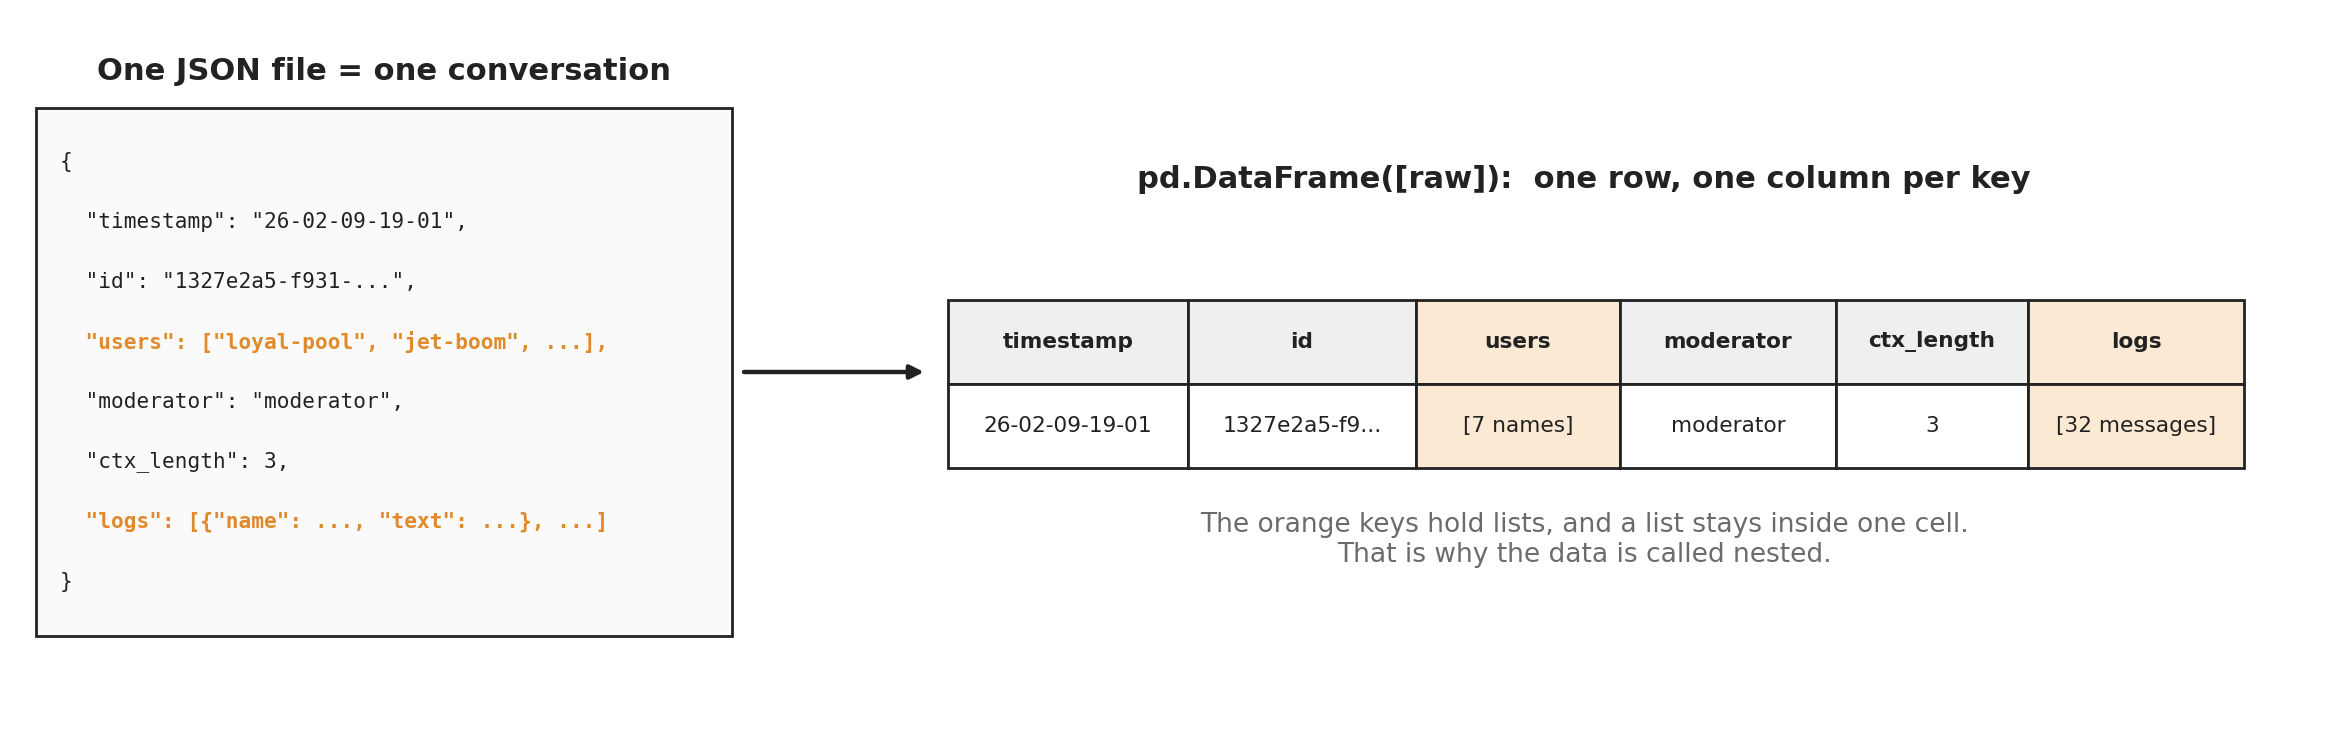

In [9]:
# the obvious attempt (this fails on purpose)
# pd.read_json(first_file)

In [10]:
# wrap the dict in a list: one row
pd.DataFrame([raw])

,timestamp,id,users,moderator,ctx_length,logs
0,26-02-09-19-01,1327e2a5-f931-4212-a1d9-b3efb7fb5348,"[loyal-pool, jet-boom, camel-conduit, grave-co...",moderator,3,"[{'name': 'grave-convergence', 'text': 'Not al..."


### 1.4 All conversations in one table

Loop over every folder and file, add the folder name as a `condition` column (so we remember which experiment each conversation belongs to), and build the DataFrame.

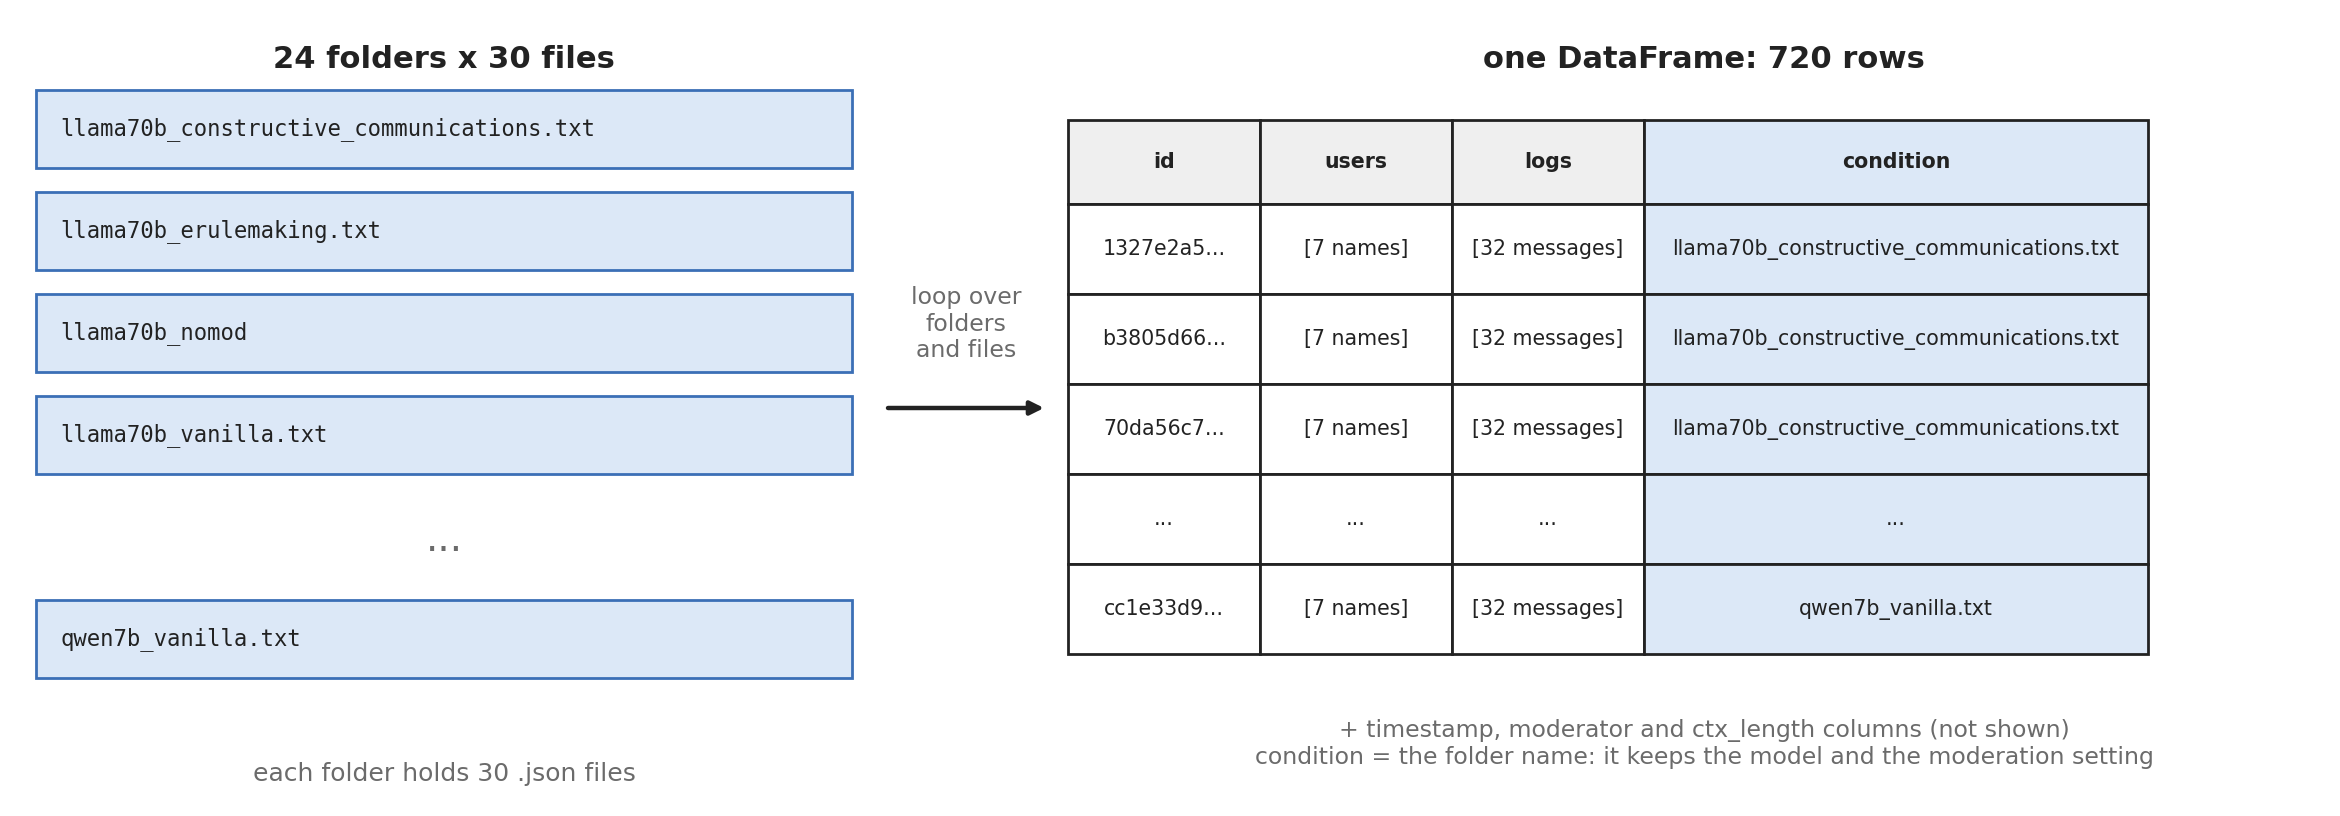

In [11]:
# load all conversations, one row each
rows = []
for folder in folders:
    for file in sorted(folder.glob("*.json")):
        with open(file) as f:
            d = json.load(f)
        d["condition"] = folder.name   # keep which experiment this file came from
        rows.append(d)

df = pd.DataFrame(rows)
print(f"df has {df.shape[0]} rows (one per conversation) and {df.shape[1]} columns")

df has 720 rows (one per conversation) and 7 columns


### Findings: Part 1

- 24 folders × 30 files = **720 conversations**, one row each, 7 columns.
- `users` and `logs` hold whole lists inside a single cell: the data is *nested*.
- `condition` records the model and the moderation setting; we use it in later parts.

Next: look at the table we built.

## Part 2 · Simple exploration

> **Goal.** Get to know a new table before touching it: size, columns, types, missing values.
>
> **What we do.** Inspect the first rows, check types and summary statistics, find the missing values, turn one column into a clean 0/1 flag, and draw the first figures.

### 2.1 A first look

`head`, `tail` and `sample` show different parts of the table. `sample` matters here because the table is sorted by folder, so the first rows alone are not representative.

In [12]:
# first and last rows
df.head()

,timestamp,id,users,moderator,ctx_length,logs,condition
0,26-02-09-19-01,1327e2a5-f931-4212-a1d9-b3efb7fb5348,"[loyal-pool, jet-boom, camel-conduit, grave-co...",moderator,3,"[{'name': 'grave-convergence', 'text': 'Not al...",llama70b_constructive_communications.txt
1,26-02-09-19-19,b3805d66-7317-44c0-99d8-d724b85d97ed,"[annoying-diffusion, noisy-centroid, eager-flo...",moderator,3,"[{'name': 'noisy-centroid', 'text': '&gt;And y...",llama70b_constructive_communications.txt
2,26-02-09-19-34,70da56c7-4b0d-4b19-823f-1b6914dc6ffa,"[exothermic-poset, coplanar-pouch, swarm-compr...",moderator,3,"[{'name': 'exothermic-poset', 'text': 'You can...",llama70b_constructive_communications.txt
3,26-02-09-19-49,56ff988c-0318-41d9-b83e-89110871dd36,"[eager-flow, kind-meridian, noisy-centroid, ex...",moderator,3,"[{'name': 'shortest-child', 'text': 'I will tr...",llama70b_constructive_communications.txt
4,26-02-09-20-07,07ad40d6-2364-4f65-bbcb-af30f253b0d9,"[succulent-sandwich, rank-ambiance, coplanar-p...",moderator,3,"[{'name': 'rank-ambiance', 'text': 'Men have h...",llama70b_constructive_communications.txt


In [13]:
df.tail(3)

,timestamp,id,users,moderator,ctx_length,logs,condition
717,26-02-22-12-19,2eb157db-1382-4901-bdff-84620c0e3454,"[humid-engine, gentle-kayak, stern-buffet, con...",moderator,3,"[{'name': 'concave-remoulade', 'text': '&gt; I...",qwen7b_vanilla.txt
718,26-02-22-12-22,449f4d2b-7443-49e0-91db-430d222df5d9,"[round-synergy, impulsive-soda, optimal-trigge...",moderator,3,"[{'name': 'bare-turbine', 'text': '&gt; It is ...",qwen7b_vanilla.txt
719,26-02-22-12-24,cc1e33d9-dcb6-4e16-95f4-7f61c7e9cb23,"[isobaric-buyer, nearest-app, spry-garden, bro...",moderator,3,"[{'name': 'spry-garden', 'text': 'Like?', 'mod...",qwen7b_vanilla.txt


In [14]:
# random rows from anywhere in the table
df.sample(5, random_state=42)

,timestamp,id,users,moderator,ctx_length,logs,condition
340,26-02-10-20-52,de0c9805-cac0-4525-b28b-c8b724f967b8,"[huge-fur, ivory-cupola, wary-saturation, toug...",moderator,3,"[{'name': 'optimal-destination', 'text': '&gt;...",mistral24b_vanilla.txt
290,26-02-22-03-55,5358d487-d8d9-4367-802d-07cf59a61ee1,"[snow-boat, nervous-transom, heather-focus, in...",moderator,3,"[{'name': 'heather-focus', 'text': 'You're usi...",mistral24b_erulemaking.txt
54,26-02-22-02-28,d294759c-2b09-442b-965a-15aa7d6dd8f4,"[frosty-percussion, burning-bulkhead, kind-chi...",moderator,3,"[{'name': 'burning-bulkhead', 'text': 'I think...",llama70b_erulemaking.txt
198,26-02-11-14-20,2746d110-6c78-42d5-8e03-7e013987d998,"[rude-birch, spicy-rotor, large-cabriolet, cel...",NaN,3,"[{'name': 'commutative-recipe', 'text': 'I'm s...",llama8b_nomod
453,26-02-11-00-07,aa435a05-b33a-4279-9aaf-0e2af619911a,"[rigid-diameter, glum-transpose, amiable-rack,...",moderator,3,"[{'name': 'tattered-pole', 'text': 'I think yo...",mistral7b_vanilla.txt


### 2.2 Columns and types

`info` lists the columns, their types and how many values are present. Types such as `object` hide what is inside the cells, so we also print the Python type of the first value in each column.

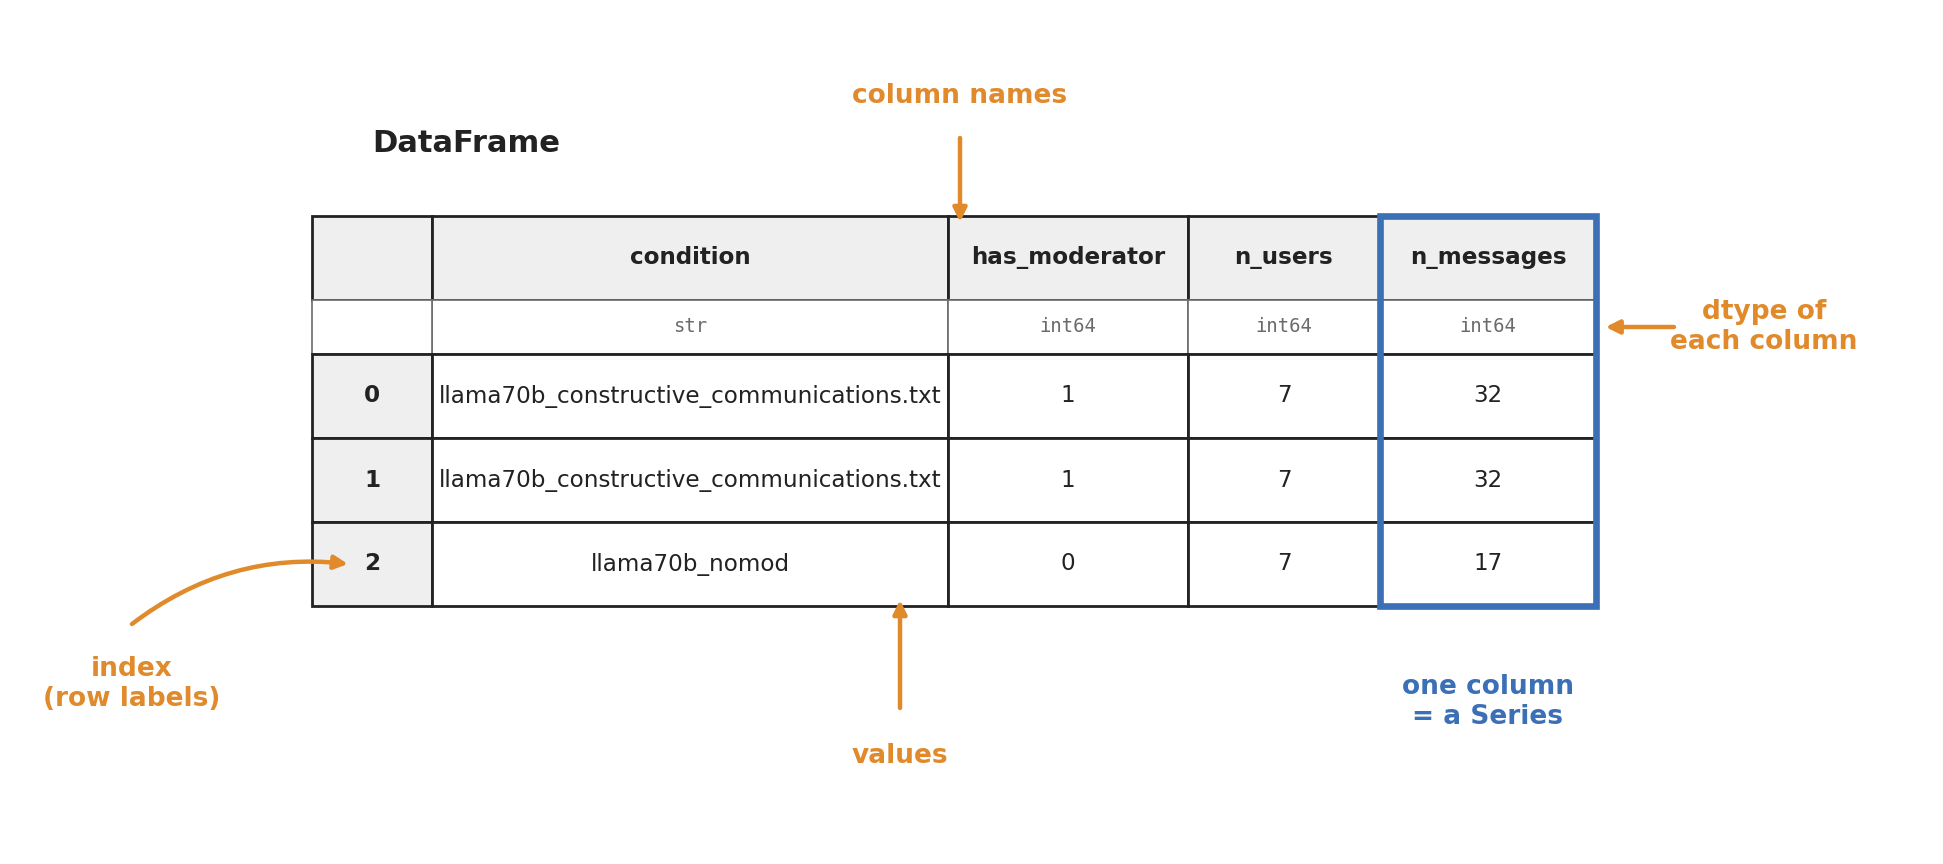

In [15]:
# columns, types, missing values
df.info()

# what is really inside each column?
print("\nPython type of the first value in each column:")
for col in df.columns:
    print(f"  {col:<11} {type(df[col][0]).__name__}")

<class 'pandas.DataFrame'>
RangeIndex: 720 entries, 0 to 719
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   timestamp   720 non-null    str   
 1   id          720 non-null    str   
 2   users       720 non-null    object
 3   moderator   540 non-null    str   
 4   ctx_length  720 non-null    int64 
 5   logs        720 non-null    object
 6   condition   720 non-null    str   
dtypes: int64(1), object(2), str(4)
memory usage: 96.6+ KB

Python type of the first value in each column:
  timestamp   str
  id          str
  users       list
  moderator   str
  ctx_length  int64
  logs        list
  condition   str


In [16]:
print(len(df.columns), "columns:", df.columns.tolist())

7 columns: ['timestamp', 'id', 'users', 'moderator', 'ctx_length', 'logs', 'condition']


### 2.3 Selecting columns

One column name gives a Series; a list of names gives a smaller DataFrame (hence the double brackets).

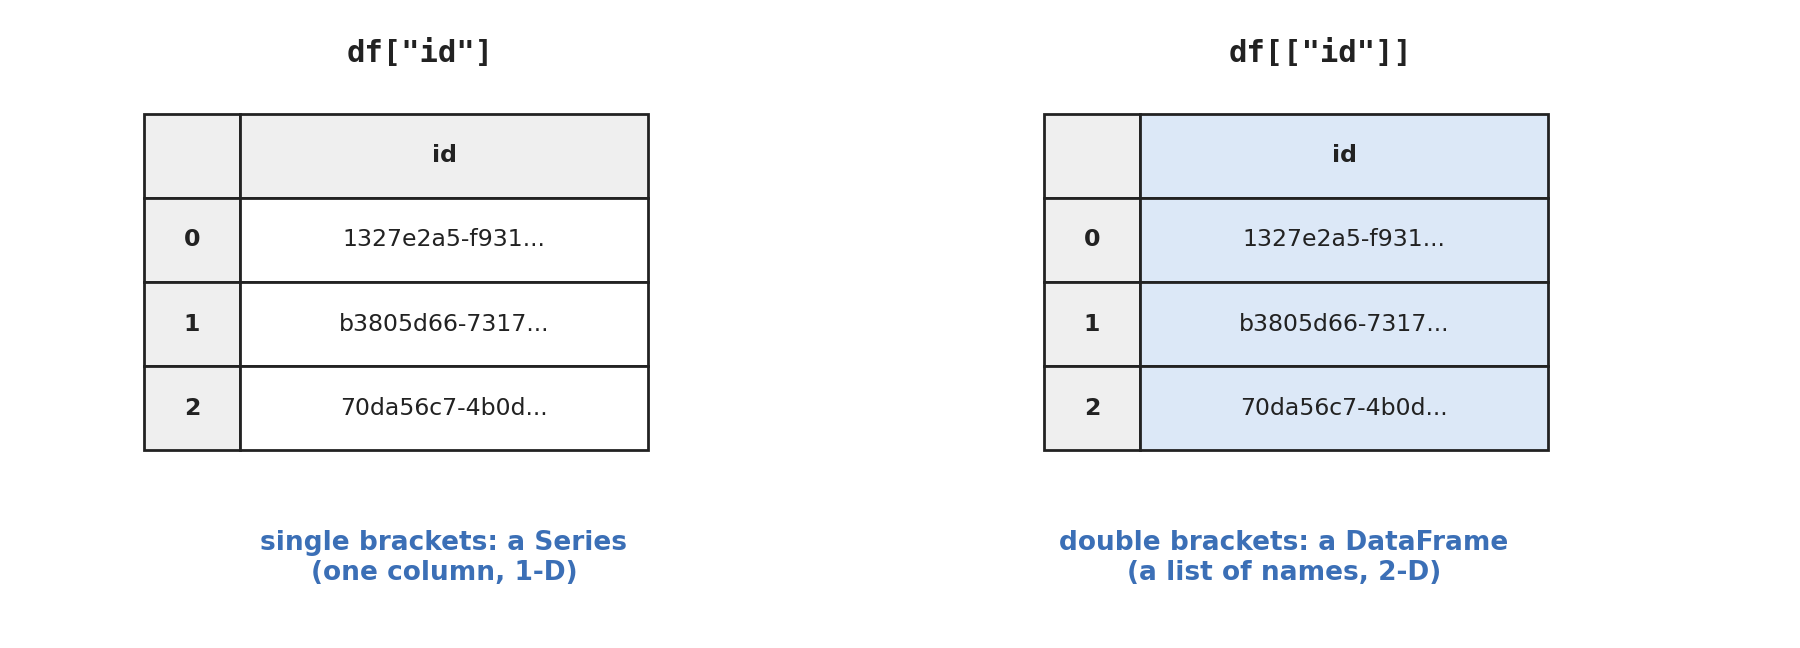

In [17]:
# one column: a Series
df["moderator"].sample(3)

314          NaN
184          NaN
531    moderator
Name: moderator, dtype: str

In [18]:
# several columns: a smaller DataFrame (note the double brackets)
df[["id", "moderator", "ctx_length"]].head()

,id,moderator,ctx_length
0,1327e2a5-f931-4212-a1d9-b3efb7fb5348,moderator,3
1,b3805d66-7317-44c0-99d8-d724b85d97ed,moderator,3
2,70da56c7-4b0d-4b19-823f-1b6914dc6ffa,moderator,3
3,56ff988c-0318-41d9-b83e-89110871dd36,moderator,3
4,07ad40d6-2364-4f65-bbcb-af30f253b0d9,moderator,3


### 2.4 Summary statistics

`describe` covers only the numeric columns by default; `include="all"` covers everything. The only numeric column, `ctx_length`, is always 3, so it tells us nothing.

In [19]:
# summary statistics (numbers only)
df.describe()

,ctx_length
count,720.0
mean,3.0
std,0.0
min,3.0
25%,3.0
50%,3.0
75%,3.0
max,3.0


In [20]:
# summary of all columns
df.describe(include="all")

,timestamp,id,users,moderator,ctx_length,logs,condition
count,720,720,720,540,720.0,720,720
unique,720,720,720,1,NaN,720,24
top,26-02-09-19-01,1327e2a5-f931-4212-a1d9-b3efb7fb5348,"[loyal-pool, jet-boom, camel-conduit, grave-co...",moderator,NaN,"[{'name': 'grave-convergence', 'text': 'Not al...",llama70b_constructive_communications.txt
freq,1,1,1,540,NaN,1,30
mean,NaN,NaN,NaN,NaN,3.0,NaN,NaN
std,NaN,NaN,NaN,NaN,0.0,NaN,NaN
min,NaN,NaN,NaN,NaN,3.0,NaN,NaN
25%,NaN,NaN,NaN,NaN,3.0,NaN,NaN
50%,NaN,NaN,NaN,NaN,3.0,NaN,NaN
75%,NaN,NaN,NaN,NaN,3.0,NaN,NaN


### 2.5 Missing values

`isna` marks every missing value and `sum` counts them in each column.

In [21]:
# missing values per column
print("number of missing values in each column:")
df.isna().sum()

number of missing values in each column:


timestamp       0
id              0
users           0
moderator     180
ctx_length      0
logs            0
condition       0
dtype: int64

**Is it really missing?** `moderator` has 180 missing values, but nothing is wrong with the data. A missing value here means the conversation had **no moderator**, so the absence itself is the signal. The other 540 rows all hold the same word, "moderator", so the column only tells us present or absent.

As `NaN` that signal is awkward to count and plot, so we turn it into an explicit 0/1 flag, `has_moderator`, and drop the original column.

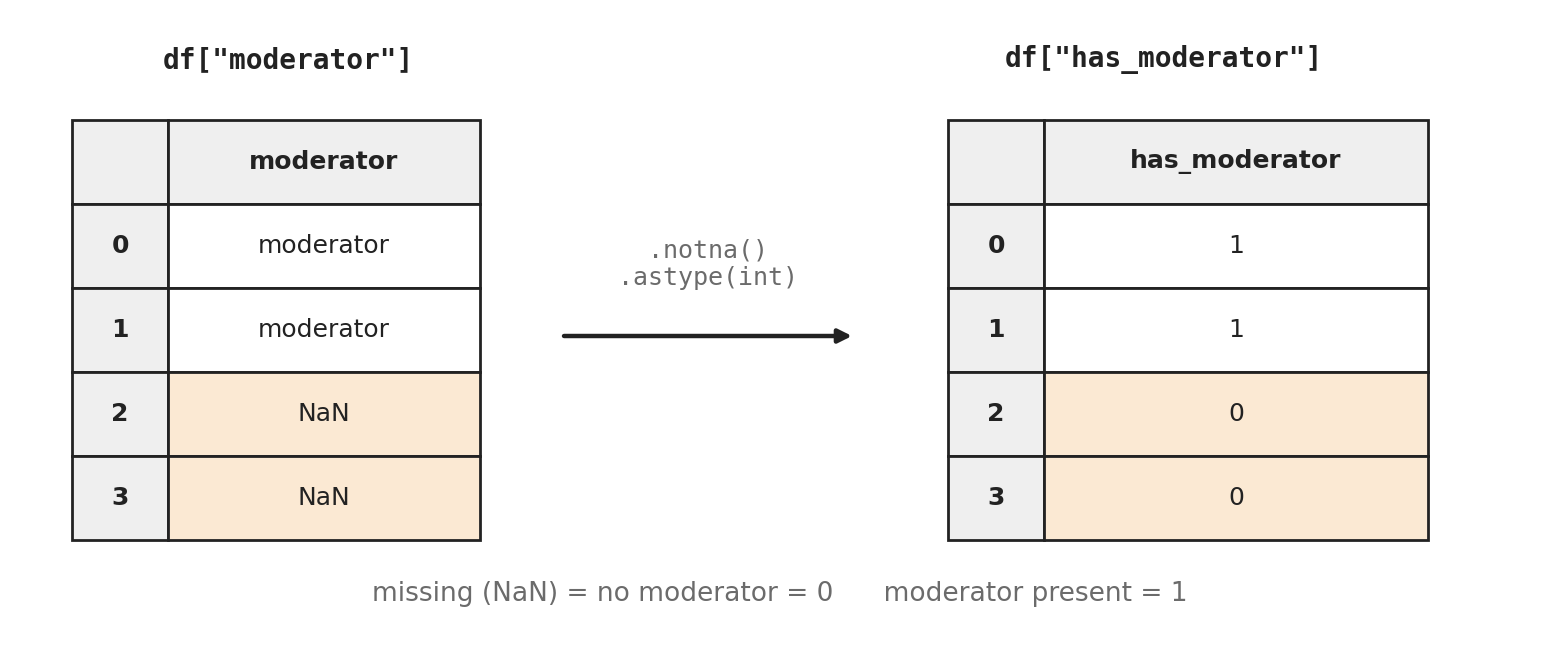

In [22]:
# convert moderator to a 0/1 flag, then drop the original column
df["has_moderator"] = df["moderator"].notna().astype(int)
df = df.drop(columns="moderator")

print("number of conversations with (1) and without (0) a moderator:")
print(df["has_moderator"].value_counts())

number of conversations with (1) and without (0) a moderator:
has_moderator
1    540
0    180
Name: count, dtype: int64


In [23]:
# the timestamp is still text: convert it to a real datetime
df["timestamp"] = pd.to_datetime(df["timestamp"], format="%y-%m-%d-%H-%M")

print("\ntimestamp is now:", df["timestamp"].dtype, "| first value:", df["timestamp"][0])


timestamp is now: datetime64[us] | first value: 2026-02-09 19:01:00


`timestamp` is now a proper datetime instead of text. Here we only convert it, so the column has the right type from now on. What we can do with dates (extract the day or the hour, compute differences) comes later, in Part 7.

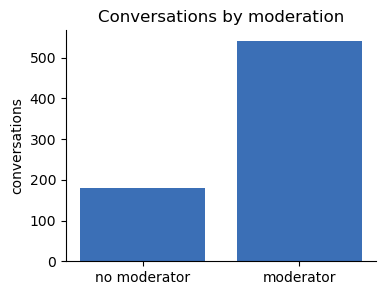

In [24]:
# the same counts as a bar chart
counts = df["has_moderator"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(4, 3))
ax.bar(["no moderator", "moderator"], counts.values, color="#3b6fb6")
ax.set_ylabel("conversations")
ax.set_title("Conversations by moderation")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

In [25]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 720 entries, 0 to 719
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   timestamp      720 non-null    datetime64[us]
 1   id             720 non-null    str           
 2   users          720 non-null    object        
 3   ctx_length     720 non-null    int64         
 4   logs           720 non-null    object        
 5   condition      720 non-null    str           
 6   has_moderator  720 non-null    int64         
dtypes: datetime64[us](1), int64(2), object(2), str(2)
memory usage: 81.9+ KB


### 2.6 Sanity checks

Before trusting a column, check which values it takes. `ctx_length` is constant and every `id` is unique, so `id` can identify a conversation.

In [26]:
# which values does ctx_length take, and how many different ids are there?
print("values of ctx_length:", df["ctx_length"].unique())
print("distinct ids:", df["id"].nunique(), "out of", len(df), "conversations")

values of ctx_length: [3]
distinct ids: 720 out of 720 conversations


### 2.7 How long are the conversations?

A histogram of the number of messages in each conversation, and its summary statistics.

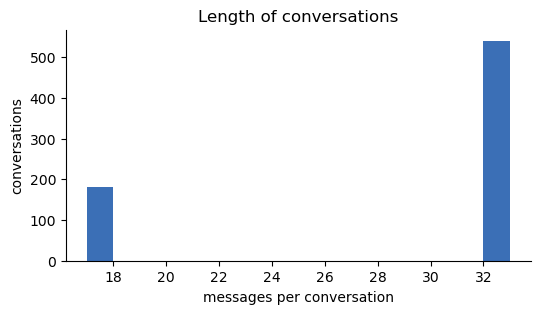

In [27]:
# how long are the conversations? (number of messages in each)
n_messages = df["logs"].str.len()

fig, ax = plt.subplots(figsize=(6, 3))
ax.hist(n_messages, bins=range(n_messages.min(), n_messages.max() + 2), color="#3b6fb6")
ax.set_xlabel("messages per conversation")
ax.set_ylabel("conversations")
ax.set_title("Length of conversations")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

In [28]:
print("summary of the number of messages per conversation:")
df["logs"].str.len().describe()

summary of the number of messages per conversation:


count    720.000000
mean      28.250000
std        6.499706
min       17.000000
25%       28.250000
50%       32.000000
75%       32.000000
max       32.000000
Name: logs, dtype: float64

### 2.8 Picking out one cell: `loc` and `iloc`

The `logs` cell of the first conversation is a list of 32 messages, each one a dict. `loc` selects by label and `iloc` by position (Part 3 goes deeper). After filtering, labels and positions stop matching.

In [29]:
# the same cell, selected two ways
by_label = df.loc[0, "logs"]      # row label 0, column named "logs"
by_position = df.iloc[0, 4]       # row position 0, column position 4

print("loc  picked a", type(by_label).__name__, "with", len(by_label), "items")
print("iloc picked a", type(by_position).__name__, "with", len(by_position), "items")

# after filtering, labels and positions no longer match
no_mod = df[df["has_moderator"] == 0]
print("\nafter filtering to the conversations without a moderator:")
print("  the first row has label", no_mod.index[0], "but position 0")
print("  iloc[0] returns the row labelled", no_mod.iloc[0].name)

print("\nthe first message of the first conversation:")
by_label[0]

loc  picked a list with 32 items
iloc picked a list with 32 items

after filtering to the conversations without a moderator:
  the first row has label 60 but position 0
  iloc[0] returns the row labelled 60

the first message of the first conversation:


{'name': 'grave-convergence',
 'text': "Not all Trump voters do it based out of hate and fear. What about all of his other messages? Making trade deals that benefit America, putting our citizens first, enforcing immigration laws that already exist, protecting 2A, getting NATO countries to pay what they're actually required to pay, and getting jobs back. You're not wrong a good portion of votes for him are out of fear and hatred but it is dishonest to say that's all he offers. I'd say the main appeal is the anti-establishment aspect of",
 'model': 'hardcoded',
 'prompt': ''}

In [30]:
# one message, field by field
print("speaker:   ", by_label[1]["name"])
print("written by:", by_label[1]["model"])

speaker:    camel-conduit
written by: hardcoded


### 2.9 Looping over rows

`iterrows` visits one row at a time. It is fine for a quick look but slow on large tables, where we prefer operations on whole columns.

In [31]:
# loop over rows
for i, row in df.head(3).iterrows():
    print(f"row {i}: id {row['id'][:8]}... | {len(row['users'])} users | {len(row['logs'])} messages")

row 0: id 1327e2a5... | 7 users | 32 messages
row 1: id b3805d66... | 7 users | 32 messages
row 2: id 70da56c7... | 7 users | 32 messages


### 2.10 A first question about the messages

`apply` runs a function on every cell of a column. Here it picks the model that wrote the last message of each conversation: every model ends 120 conversations (6 × 120 = 720), a first hint that the conditions are balanced.

In [32]:
# who wrote the last message of each conversation?
print("model that wrote the last message -> number of conversations:")
df["logs"].apply(lambda msgs: msgs[-1]["model"]).value_counts()

model that wrote the last message -> number of conversations:


logs
llama70b      120
llama8b       120
mistral24b    120
mistral7b     120
qwen32b       120
qwen7b        120
Name: count, dtype: int64

### Findings: Part 2

- 720 conversations, every `id` unique. `ctx_length` is always 3 and carries no information.
- 180 conversations (25%) have no moderator, 540 have one.
- The number of messages per conversation ranges from 17 to 32, and most have 32.
- The interesting data is nested inside `users` and `logs`. Part 3 learns to zoom into the table, and Part 4 flattens it.

## Part 3 · Selecting rows and columns

> **Goal.** See how flexibly pandas lets us pick exactly the part of a table we need.
>
> **What we do.** Build a few numeric columns, then select columns, rows, and rows and columns together, by label and by position. We use the selections to draw two figures that reveal how the experiment is organised.

### 3.1 Making numbers to select from

Message, user and moderator-message counts for every conversation, built with `.str.len()` and `apply`.

In [33]:
# part 2 had a histogram of messages per conversation
# turn it into a real column, and add two more counts to work with
df["n_messages"] = df["logs"].str.len()
df["n_users"] = df["users"].str.len()
df["n_mod_messages"] = df["logs"].apply(lambda msgs: sum(m["name"] == "moderator" for m in msgs))

df[["n_messages", "n_users", "n_mod_messages"]].head()

,n_messages,n_users,n_mod_messages
0,32,7,15
1,32,7,15
2,32,7,15
3,32,7,15
4,32,7,15


### 3.2 A smaller working table

The nested columns are heavy to print. A list of column names keeps only the numeric ones.

In [34]:
# a smaller working table: leave out the nested columns, keep the numbers
summary = df[["condition", "has_moderator", "n_users", "n_messages", "n_mod_messages"]]
summary.head()

,condition,has_moderator,n_users,n_messages,n_mod_messages
0,llama70b_constructive_communications.txt,1,7,32,15
1,llama70b_constructive_communications.txt,1,7,32,15
2,llama70b_constructive_communications.txt,1,7,32,15
3,llama70b_constructive_communications.txt,1,7,32,15
4,llama70b_constructive_communications.txt,1,7,32,15


### 3.3 Selecting columns

Besides a list, `loc` accepts a *range* of column names, from one to another (both included).

In [35]:
# columns: with loc we can also take a range of names, from one to another
summary.loc[:, "n_users":"n_mod_messages"].head()

,n_users,n_messages,n_mod_messages
0,7,32,15
1,7,32,15
2,7,32,15
3,7,32,15
4,7,32,15


### 3.4 Selecting rows

Rows can be sliced by **position** (`iloc`, end excluded, like Python lists) or by **label** (`loc`, end *included*). The same-looking slice returns 5 rows with `iloc` and 6 with `loc`.

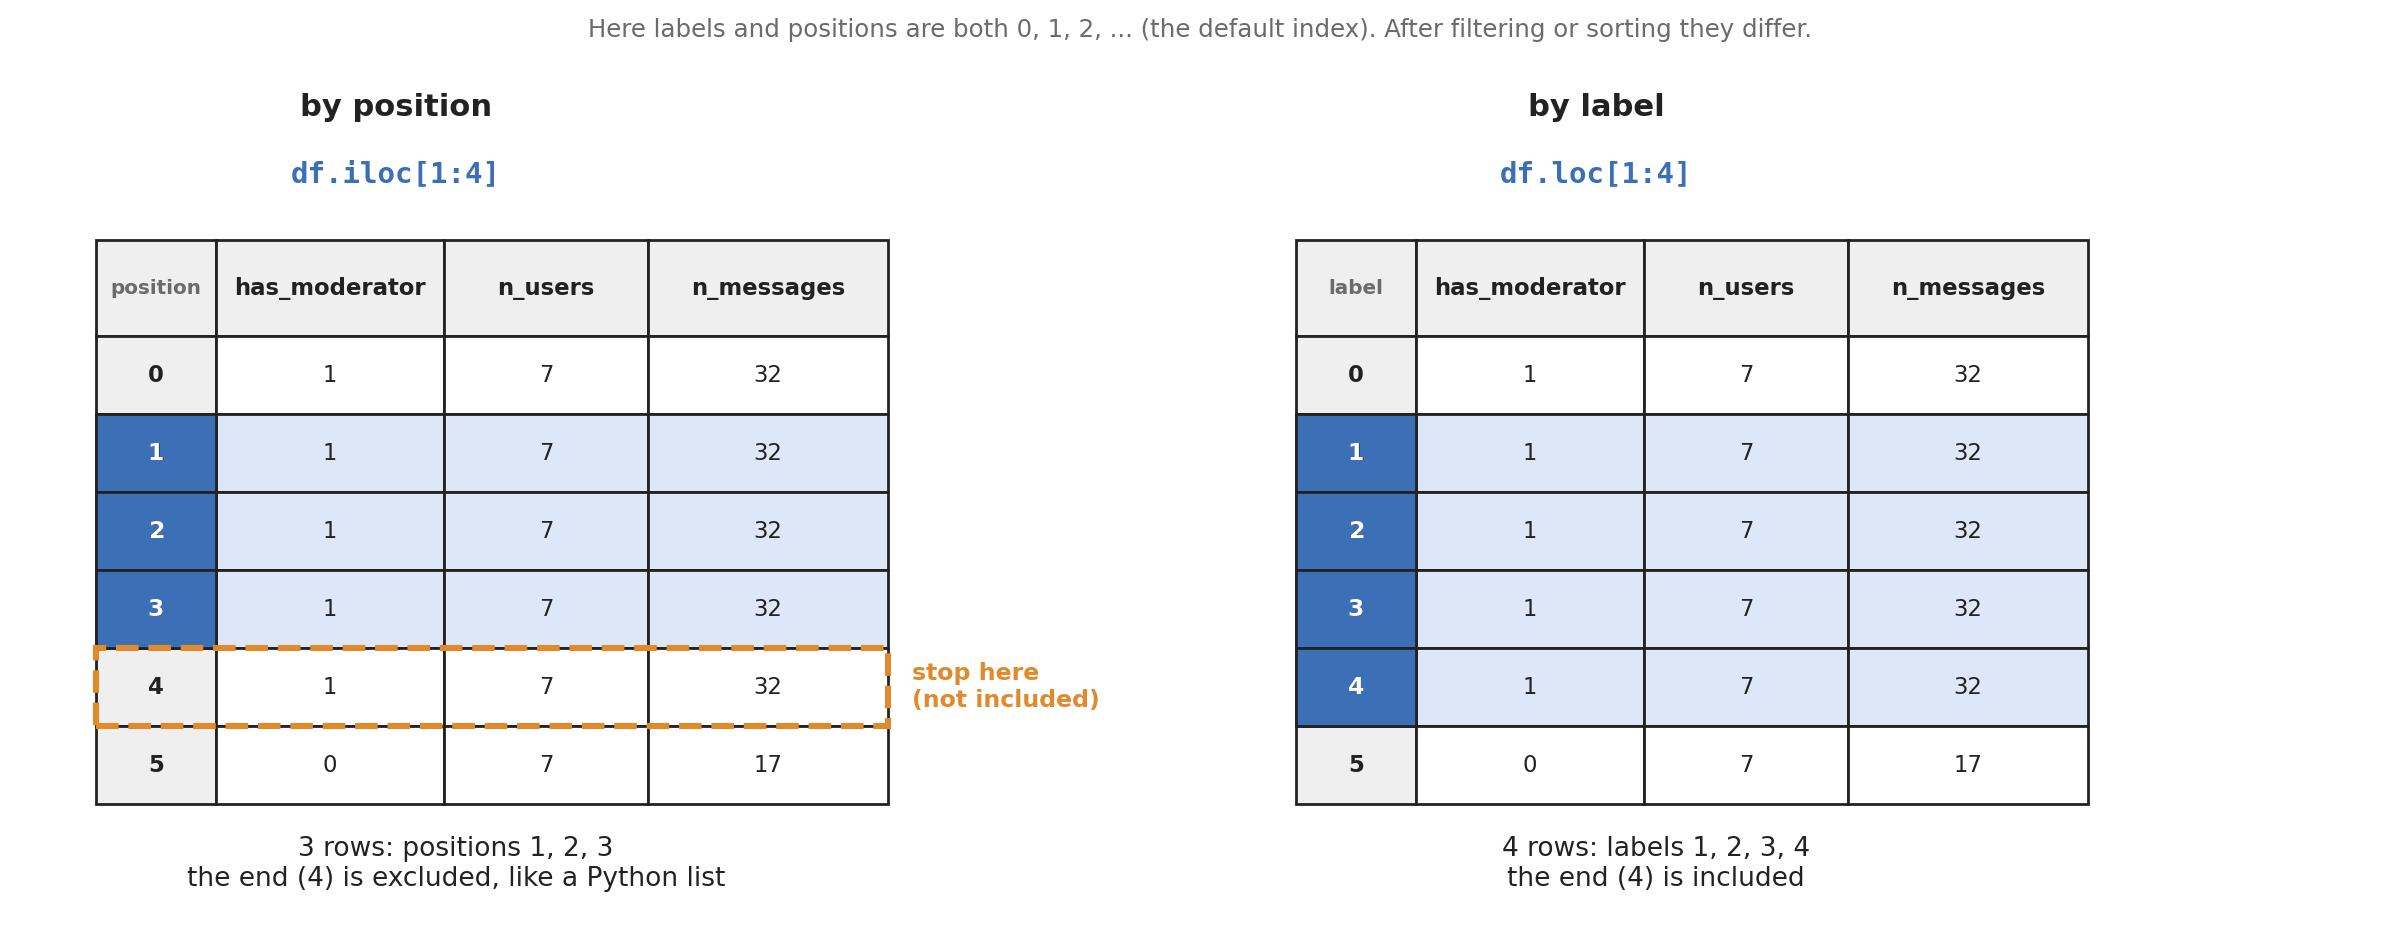

In [36]:
# rows: slicing by position excludes the end, slicing by label includes it
print("iloc[10:15] gives", len(summary.iloc[10:15]), "rows (positions 10 to 14)")
print("loc[10:15]  gives", len(summary.loc[10:15]), "rows (labels 10 to 15)")

summary.iloc[10:15]

iloc[10:15] gives 5 rows (positions 10 to 14)
loc[10:15]  gives 6 rows (labels 10 to 15)


,condition,has_moderator,n_users,n_messages,n_mod_messages
10,llama70b_constructive_communications.txt,1,7,32,15
11,llama70b_constructive_communications.txt,1,7,32,15
12,llama70b_constructive_communications.txt,1,7,32,15
13,llama70b_constructive_communications.txt,1,7,32,15
14,llama70b_constructive_communications.txt,1,7,32,15


### 3.5 Rows and columns together

Give `loc` or `iloc` a row selection, a comma, then a column selection. The next two cells pick the same cells in the two ways.

In [37]:
# rows and columns together, by label...
summary.loc[10:14, ["condition", "n_messages"]]

,condition,n_messages
10,llama70b_constructive_communications.txt,32
11,llama70b_constructive_communications.txt,32
12,llama70b_constructive_communications.txt,32
13,llama70b_constructive_communications.txt,32
14,llama70b_constructive_communications.txt,32


In [38]:
# ...and by position (the same cells)
summary.iloc[10:15, [0, 3]]

,condition,n_messages
10,llama70b_constructive_communications.txt,32
11,llama70b_constructive_communications.txt,32
12,llama70b_constructive_communications.txt,32
13,llama70b_constructive_communications.txt,32
14,llama70b_constructive_communications.txt,32


### 3.6 Patterns of rows

A third slice number is a step: `::100` takes every 100th row. Negative positions count from the end.

In [39]:
# every 100th row, and the last three rows
print("the last three rows:")
print(summary.iloc[-3:])

print("\nevery 100th row:")
summary.iloc[::100]

the last three rows:
              condition  has_moderator  n_users  n_messages  n_mod_messages
717  qwen7b_vanilla.txt              1        7          32              15
718  qwen7b_vanilla.txt              1        7          32              15
719  qwen7b_vanilla.txt              1        7          32              15

every 100th row:


,condition,has_moderator,n_users,n_messages,n_mod_messages
0,llama70b_constructive_communications.txt,1,7,32,15
100,llama70b_vanilla.txt,1,7,32,15
200,llama8b_nomod,0,7,17,0
300,mistral24b_nomod,0,7,17,0
400,mistral7b_erulemaking.txt,1,7,32,15
500,qwen32b_constructive_communications.txt,1,7,32,15
600,qwen7b_constructive_communications.txt,1,7,32,15
700,qwen7b_vanilla.txt,1,7,32,15


### 3.7 A single value

`at` (by label) and `iat` (by position) are the fast way to read one cell.

In [40]:
# a single value: at (by label) and iat (by position)
print("at  (row label 0, column name):    ", summary.at[0, "n_messages"])
print("iat (row position 0, column position 3):", summary.iat[0, 3])

at  (row label 0, column name):     32
iat (row position 0, column position 3): 32


### 3.8 Zooming in: how is the table organised?

The rows are ordered by folder, 30 conversations each. Selecting the first 120 rows with `iloc` and plotting `n_messages` shows four folders one after the other, and one of them is clearly shorter.

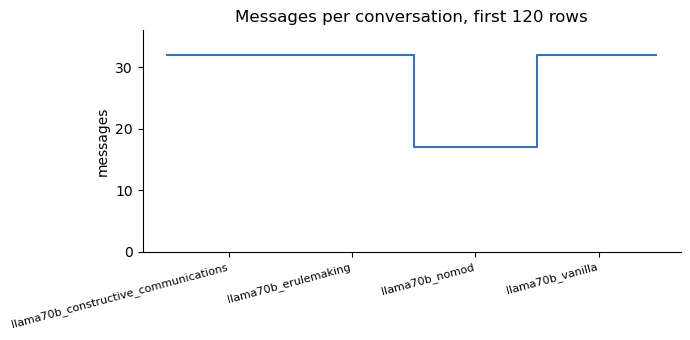

In [41]:
# the table is ordered by folder, 30 conversations each
# zooming in on the first 120 rows shows four folders one after the other
first_120 = summary.iloc[:120]
labels = [c.replace(".txt", "") for c in first_120["condition"].iloc[::30]]

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(first_120.index, first_120["n_messages"], color="#3b6fb6", drawstyle="steps-post")
ax.set_xticks(range(15, 120, 30), labels, rotation=15, ha="right", fontsize=8)
ax.set_ylim(0, 36)
ax.set_ylabel("messages")
ax.set_title("Messages per conversation, first 120 rows")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

### 3.9 Selecting by name

The short folder is a `nomod` one. If `condition` becomes the row labels (the index), we can select a whole folder by its name. Label slices need a **sorted** index, so we sort it first.

In [42]:
# the dip is the nomod folder: use condition as the row labels to select it by name
by_cond = summary.set_index("condition").sort_index()

print("the first 3 conversations of llama8b_nomod:")
by_cond.loc["llama8b_nomod"].head(3)

the first 3 conversations of llama8b_nomod:


,has_moderator,n_users,n_messages,n_mod_messages
condition,,,,
llama8b_nomod,0,7,17,0
llama8b_nomod,0,7,17,0
llama8b_nomod,0,7,17,0


In [43]:
# one label and one column: the label is shared by 30 conversations, so we get 30 values
nomod_messages = by_cond.loc["llama8b_nomod", "n_messages"]

print(len(nomod_messages), "values selected, all from the folder llama8b_nomod")
print("distinct values:", nomod_messages.unique())
nomod_messages.head()

30 values selected, all from the folder llama8b_nomod
distinct values: [17]


condition
llama8b_nomod    17
llama8b_nomod    17
llama8b_nomod    17
llama8b_nomod    17
llama8b_nomod    17
Name: n_messages, dtype: int64

In [44]:
# a range of labels (first and last both included) and a list of columns
# this only works because the index is sorted
selected = by_cond.loc["llama70b_vanilla.txt":"llama8b_erulemaking.txt", ["n_messages", "n_mod_messages"]]

print("the rows come from these folders:")
print(selected.index.value_counts().sort_index())
print("\nshape:", selected.shape, "(rows, columns)")
selected.head(3)

the rows come from these folders:
condition
llama70b_vanilla.txt                       30
llama8b_constructive_communications.txt    30
llama8b_erulemaking.txt                    30
Name: count, dtype: int64

shape: (90, 2) (rows, columns)


,n_messages,n_mod_messages
condition,,
llama70b_vanilla.txt,32,15
llama70b_vanilla.txt,32,15
llama70b_vanilla.txt,32,15


### 3.10 One conversation per condition

Step slicing gives the first row of every folder, and the bar chart shows the pattern across all 24 conditions.

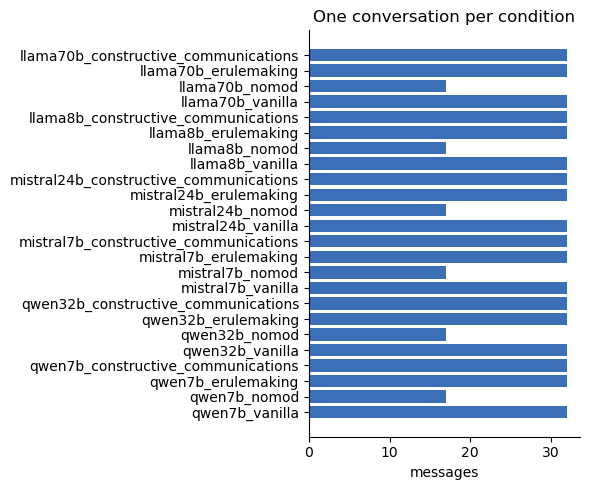

In [45]:
# one conversation per condition: the first row of every block of 30
one_each = by_cond.iloc[::30]

fig, ax = plt.subplots(figsize=(6, 5))
ax.barh([c.replace(".txt", "") for c in one_each.index], one_each["n_messages"], color="#3b6fb6")
ax.invert_yaxis()
ax.set_xlabel("messages")
ax.set_title("One conversation per condition")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

### Findings: Part 3

- The table is ordered by folder: 30 consecutive rows per condition.
- `iloc` selects by position and excludes the end; `loc` selects by label and includes it; label slices need a sorted index.
- Moderated conversations always have 32 messages, `nomod` ones 17. The experiment fixed the length, so these columns hold little variation.
- The real variation is inside the messages: Part 4 flattens `logs` to one row per message.

## Part 4 · Math and statistics

> **Goal.** Summarise data with pandas statistics, and change values in a column.
>
> **What we do.** Try the statistics on the small summary table, see why it is not enough, flatten the messages into their own table, measure their length, and finish by changing values with `replace`, `map` and `clip`.

### 4.1 Statistics on the summary table

`describe` computes count, mean, std, min, quartiles and max for every numeric column at once.

In [46]:
# part 3 left us with a few numeric columns: describe them all at once
summary.describe()

,has_moderator,n_users,n_messages,n_mod_messages
count,720.000000,720.0,720.000000,720.000000
mean,0.750000,7.0,28.250000,11.250000
std,0.433314,0.0,6.499706,6.499706
min,0.000000,7.0,17.000000,0.000000
25%,0.750000,7.0,28.250000,11.250000
50%,1.000000,7.0,32.000000,15.000000
75%,1.000000,7.0,32.000000,15.000000
max,1.000000,7.0,32.000000,15.000000


### 4.2 One statistic at a time

Each statistic is also its own method. `mode` returns a Series because several values can tie.

In [47]:
# the same statistics, one at a time
col = summary["n_messages"]

print("min   ", col.min())
print("max   ", col.max())
print("mean  ", col.mean())
print("median", col.median())
print("mode  ", col.mode()[0])   # mode returns a Series (there can be ties), take the first
print("count ", col.count())
print("sum   ", col.sum())

min    17
max    32
mean   28.25
median 32.0
mode   32
count  720
sum    20340


### 4.3 Sums and means of a 0/1 flag

On a column of 0s and 1s, `sum` counts the ones and `mean` is their share.

In [48]:
# on a 0/1 flag, sum counts the ones and mean gives their share
print(summary["has_moderator"].sum(), "moderated conversations")
print(summary["has_moderator"].mean(), "share of all conversations")

540 moderated conversations
0.75 share of all conversations


**What does 0.75 mean?** It is a fraction: 540 moderated conversations out of 720, so **3 out of every 4** conversations (75%) have a moderator.

This is exactly what we should expect. Every model was run with 4 settings, and only one of them, `nomod`, has no moderator, so 3 of the 4 settings are moderated: 3/4 = 0.75.

That makes it a useful habit: **we use data manipulation to verify the data, not only to analyse it.** When a number we compute matches what the design predicts, we gain confidence in the dataset and in the way we loaded it. If it did not match, we would look for the problem before going any further.

### 4.4 Why this is not enough

A mean of 28.25 messages describes no real conversation: lengths are only 17 or 32.

The mean, the median and the std each squeeze a whole column into one number, and very different data can give the same numbers. Here the mean (28.25) and the std (6.5) say nothing about there being only two lengths, and the median (32) hides that a quarter of the conversations are shorter.

So **never trust a summary statistic on its own: look at the whole distribution.** Count the values (as in the next cell), draw a histogram or a box plot (we do both later in this part), and only then decide which statistic describes the data well.

In [49]:
# but the mean of 28.25 describes no real conversation: there are only two lengths
# the experiment fixed them, so there is little left to measure at this level
print("number of conversations for each length:")
summary["n_messages"].value_counts()

number of conversations for each length:


n_messages
32    540
17    180
Name: count, dtype: int64

### 4.5 One row per message

`explode` gives every message its own row. Each message is still a dict, so we pick out its keys (`name`, `text`, `model`) one by one with `.str[...]`, the same `.str` we used for `.str.len()`. The result, `msgs`, is the main table for the rest of the lab.

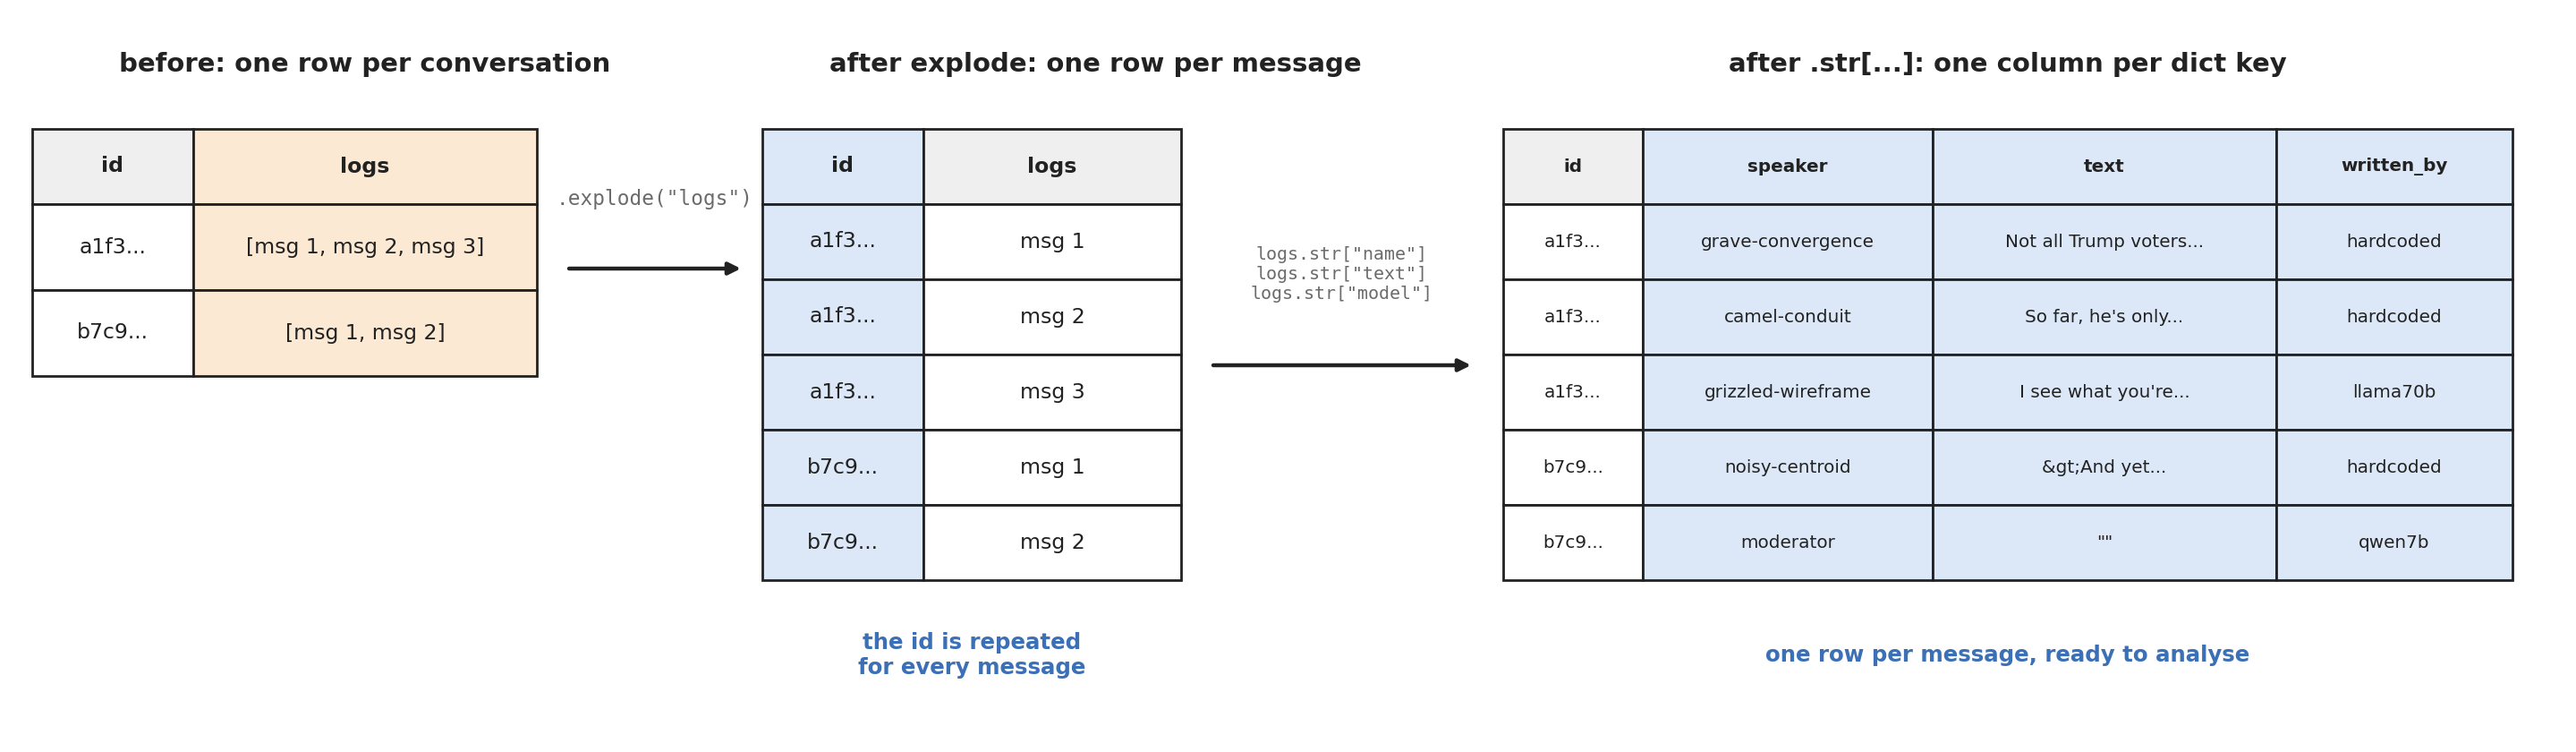

In [50]:
# the variation is inside the messages: flatten to one row per message
msgs = df[["id", "condition", "has_moderator", "logs"]].explode("logs", ignore_index=True)
print(f"{msgs.shape[0]} messages (rows) from {df.shape[0]} conversations")

20340 messages (rows) from 720 conversations


In [ ]:
# each message is still a dict: pick its keys out as new columns
# (the same .str as before also works on dicts: .str["name"] takes the key "name" of every dict)
msgs["speaker"] = msgs["logs"].str["name"]
msgs["text"] = msgs["logs"].str["text"]
msgs["written_by"] = msgs["logs"].str["model"]

# the dicts are no longer needed; id is renamed to say what it identifies
msgs = msgs.drop(columns="logs").rename(columns={"id": "conv_id"})
msgs.head()

### 4.6 A number for every message

`.str.len()` also works on text. The length of each message in characters gives the statistics real variation to work with.

In [52]:
# a number for every message: its length in characters
# (the same .str.len() as before, now on text)
msgs["n_chars"] = msgs["text"].str.len()
print("summary of message length (characters):")
msgs["n_chars"].describe()

summary of message length (characters):


count    20340.000000
mean       339.093510
std        278.668716
min          2.000000
25%        206.000000
50%        315.000000
75%        451.000000
max       7483.000000
Name: n_chars, dtype: float64

### 4.7 Statistics on message length

The mean is above the median, so a few very long messages pull it up. The histogram shows this tail, and a spike of very short messages at the left.

In [53]:
# now the statistics have something to say
chars = msgs["n_chars"]

print("message length in characters")
print("min     ", chars.min())
print("max     ", chars.max())
print("mean    ", round(chars.mean(), 1))
print("median  ", chars.median())
print("std     ", round(chars.std(), 1))
print("mode    ", chars.mode()[0])
print("90th pct", chars.quantile(0.9), "  (90% of messages are shorter than this)")

message length in characters
min      2
max      7483
mean     339.1
median   315.0
std      278.7
mode     2
90th pct 576.0   (90% of messages are shorter than this)


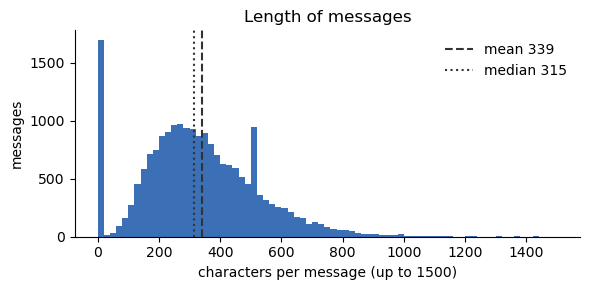

In [54]:
# the mean is above the median: a few very long messages pull it up
# the spike at the far left is the mode, the very shortest messages
fig, ax = plt.subplots(figsize=(6, 3))
ax.hist(chars, bins=75, range=(0, 1500), color="#3b6fb6")
ax.axvline(chars.mean(), color="#333333", linestyle="--", label=f"mean {chars.mean():.0f}")
ax.axvline(chars.median(), color="#333333", linestyle=":", label=f"median {chars.median():.0f}")
ax.set_xlabel("characters per message (up to 1500)")
ax.set_ylabel("messages")
ax.set_title("Length of messages")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

### 4.8 The extremes

`idxmin` and `idxmax` return the row label of the smallest and largest value, which we use to read the actual messages. The shortest are just `""`: the moderator is allowed to stay silent, and so (as it turns out) are the users sometimes.

In [55]:
# what are the extremes? idxmin / idxmax return the row label of the smallest / largest value
for name, label in [("shortest", chars.idxmin()), ("longest", chars.idxmax())]:
    print(name, "| row", label, "|", chars[label], "characters")
    print(repr(msgs.loc[label, "text"][:150]))
    print()

shortest | row 25 | 2 characters
'""'

longest | row 17501 | 7483 characters
'""\n``` @strong-limousine, thank you for your supportive response. It\'s great to see such constructive engagement in the discussion. Let\'s keep the con'



### 4.9 Counting values in a text column

`nunique` and `value_counts` work on text too. One speaker, the moderator, writes about 40% of all messages.

In [56]:
# counting also works on text: who speaks the most?
print(msgs["speaker"].nunique(), "different speakers")
print("\nmessages per speaker (the five most active):")
print(msgs["speaker"].value_counts().head())

# normalize=True gives shares instead of counts
print("\nshare of all messages (the top three):")
msgs["speaker"].value_counts(normalize=True).head(3)

1880 different speakers

messages per speaker (the five most active):
speaker
moderator           8100
gilded-grantor        26
quiet-right           26
exothermic-poset      24
mature-berm           24
Name: count, dtype: int64

share of all messages (the top three):


speaker
moderator         0.398230
gilded-grantor    0.001278
quiet-right       0.001278
Name: proportion, dtype: float64

### 4.10 Changing values

Three tools: `replace` swaps one value for another, `map` applies a dictionary, and `clip` caps extreme values.

In [57]:
# changing values: replace one value by another
# the opening comments come from real data, not from a model
msgs["written_by"] = msgs["written_by"].replace("hardcoded", "real comment")
print("number of messages for each writer:")
msgs["written_by"].value_counts()

number of messages for each writer:


written_by
llama70b        3150
llama8b         3150
mistral24b      3150
mistral7b       3150
qwen32b         3150
qwen7b          3150
real comment    1440
Name: count, dtype: int64

In [58]:
# changing values: map a dictionary over a column (0/1 becomes a readable label)
msgs["has_moderator"] = msgs["has_moderator"].map({0: "no", 1: "yes"})
print("number of messages, by whether the conversation had a moderator:")
msgs["has_moderator"].value_counts()

number of messages, by whether the conversation had a moderator:


has_moderator
yes    17280
no      3060
Name: count, dtype: int64

In [59]:
# changing values: clip caps the extremes, here at 1000 characters
msgs["n_chars_capped"] = msgs["n_chars"].clip(upper=1000)

# the mean barely moves, but the std (and the max) change a lot
msgs[["n_chars", "n_chars_capped"]].agg(["mean", "std", "max"])

,n_chars,n_chars_capped
mean,339.093510,332.075959
std,278.668716,192.093051
max,7483.000000,1000.000000


A box plot summarises the same numbers we computed in 4.7. The box runs from the first quartile (Q1) to the third (Q3), the line inside it is the median, the whiskers reach at most 1.5 × the box length beyond it, and every point past a whisker is drawn as an outlier.

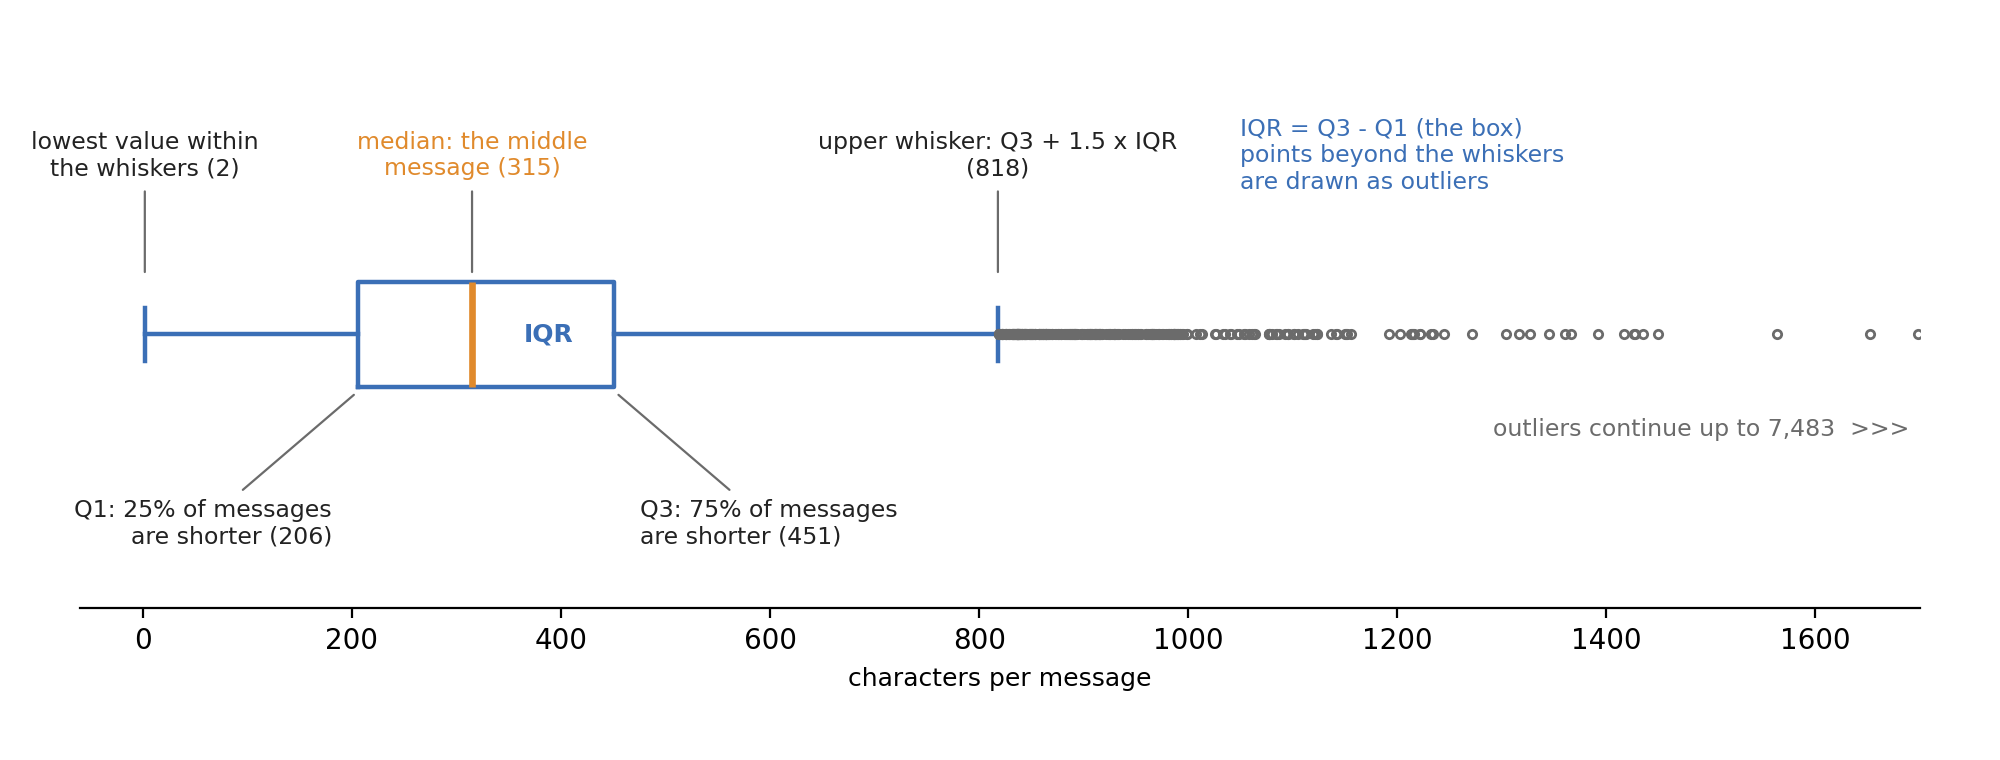

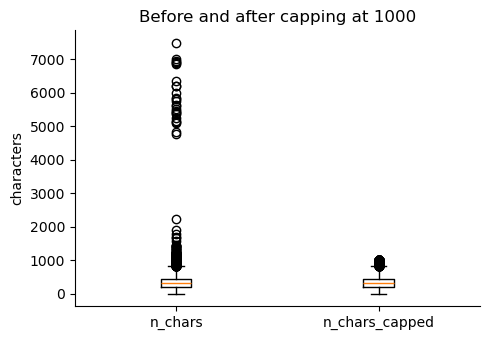

In [60]:
# the same effect as a picture: the long tail of outliers is gone
fig, ax = plt.subplots(figsize=(5, 3.5))
ax.boxplot([msgs["n_chars"], msgs["n_chars_capped"]])
ax.set_xticks([1, 2], ["n_chars", "n_chars_capped"])
ax.set_ylabel("characters")
ax.set_title("Before and after capping at 1000")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

### Findings: Part 4

- Statistics need variation: conversation length is fixed by the design, message length is not.
- Message length is right-skewed: the mean is above the median, with a long tail up to about 7,500 characters and a spike of 2-character (`""`) messages.
- The moderator writes the most: 8,100 of the 20,340 messages (40%).
- `replace`, `map` and `clip` change values without changing the structure of the table.
- `msgs` is now our main table. Part 5 filters it, for example to look at the empty messages.